In [ ]:
!nvidia-smi

Sat Sep 26 11:40:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
%%writefile Checkfile.cu
#include <bits/stdc++.h>
using namespace std;
void __global__ hello(){
  printf("Hello GPU");
}
int main(){
  hello<<<1,1>>>();
  cudaDeviceSynchronize();
  return 0;
}

Overwriting Checkfile.cu


In [ ]:
!nvcc Checkfile.cu -o C

nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).


In [ ]:
!./C

Hello GPU

In [9]:
%%writefile vecAdd.cu
#include <bits/stdc++.h>
using namespace std;
void __global__ vecAdd(float* A, float* B, float* C){
  int i = threadIdx.x;
  C[i] = B[i]+A[i];
}
int main(){
  int n = 1000;
  float *A, *B, *C;
  cudaMallocManaged(&A, n*sizeof(float));
  cudaMallocManaged(&B, n*sizeof(float));
  cudaMallocManaged(&C, n*sizeof(float));
  for(int i=0; i<n; i++){
    A[i] = i;
    B[i] = i*2;
  }
  vecAdd<<<1,n>>>(A,B,C);
  for(int i=0; i<n; i++){
    cout<<A[i]<<" "<<B[i]<<" "<<C[i]<<endl;
  }
  cout<<endl;
  cudaFree(A);
  cudaFree(B);
  cudaFree(C);
  return 0;
}

Overwriting vecAdd.cu


In [10]:
!nvcc vecAdd.cu -o v
!./v

nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).
0 0 0
1 2 3
2 4 6
3 6 9
4 8 12
5 10 15
6 12 18
7 14 21
8 16 24
9 18 27
10 20 30
11 22 33
12 24 36
13 26 39
14 28 42
15 30 45
16 32 48
17 34 51
18 36 54
19 38 57
20 40 60
21 42 63
22 44 66
23 46 69
24 48 72
25 50 75
26 52 78
27 54 81
28 56 84
29 58 87
30 60 90
31 62 93
32 64 96
33 66 99
34 68 102
35 70 105
36 72 108
37 74 111
38 76 114
39 78 117
40 80 120
41 82 123
42 84 126
43 86 129
44 88 132
45 90 135
46 92 138
47 94 141
48 96 144
49 98 147
50 100 150
51 102 153
52 104 156
53 106 159
54 108 162
55 110 165
56 112 168
57 114 171
58 116 174
59 118 177
60 120 180
61 122 183
62 124 186
63 126 189
64 128 192
65 130 195
66 132 198
67 134 201
68 136 204
69 138 207
70 140 210
71 142 213
72 144 216
73 146 219
74 148 222
75 150 225
76 152 228
77 154 231
78 156 234
79 158 237
80 160 240
81 162 243
82 164 246
83 

In [22]:
%%writefile dotProd.cu
#include <bits/stdc++.h>
using namespace std;

void __global__ dotProd(float *A, float *B, float *C){
  int i = threadIdx.x;
  C[i] = A[i]*B[i];
}

int main(){
  float *A, *B, *C;
  int n = 1000;
  cudaMallocManaged(&A, n*sizeof(float));
  cudaMallocManaged(&B, n*sizeof(float));
  cudaMallocManaged(&C, n*sizeof(float));
  for(int i = 0; i < n; i++){
    A[i] = 1;
    B[i] = 2;
  }
  dotProd<<<1,n>>>(A,B,C);
  for(int i = 0; i < n; i++){
    cout<<A[i]<<" "<<B[i]<<" "<<C[i]<<endl;
  }
  cout<<endl;
  cudaFree(A);
  cudaFree(B);
  cudaFree(C);
  return 0;
}

Overwriting dotProd.cu


In [23]:
!nvcc dotProd.cu -o d
!./d

nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2 2
1 2

In [24]:
import numpy as np
try:
    import pycuda.driver as cuda
    import pycuda.autoinit
    from pycuda.compiler import SourceModule
except ImportError:
    # Install pycuda if not present
    !pip install pycuda
    import pycuda.driver as cuda
    import pycuda.autoinit
    from pycuda.compiler import SourceModule

# Define the CUDA kernels provided by the user
mod = SourceModule("""
__global__ void dotProd(float *A, float *B, float *C) {
    int i = threadIdx.x;
    C[i] = A[i] * B[i];
}

__global__ void vecAdd(float *A, float *B, float *C) {
    int i = threadIdx.x;
    C[i] = B[i] + A[i];
}
""")

dot_prod_kernel = mod.get_function("dotProd")
vec_add_kernel = mod.get_function("vecAdd")

def gpu_matrix_mul(matrix_A, matrix_B):
    """
    Performs matrix multiplication using user's vecAdd and dotProd kernels.
    """
    A = np.array(matrix_A, dtype=np.float32)
    B = np.array(matrix_B, dtype=np.float32)

    M, K = A.shape
    K_b, N = B.shape
    assert K == K_b, "Matrix dimensions do not match for multiplication!"

    # Prepare output matrix
    C = np.zeros((M, N), dtype=np.float32)

    # Temporary GPU buffers for one dot product computation
    temp_mult_gpu = cuda.mem_alloc(K * 4)

    for i in range(M):
        for j in range(N):
            # Extract row from A and column from B
            row_A = A[i, :]
            col_B = B[:, j]

            # Send vectors to GPU
            row_A_gpu = cuda.to_device(row_A)
            col_B_gpu = cuda.to_device(col_B)

            # Step 1: Element-wise multiplication (dotProd)
            dot_prod_kernel(row_A_gpu, col_B_gpu, temp_mult_gpu, block=(K, 1, 1), grid=(1, 1))

            # Retrieve the element-wise products back to CPU to sum them up using our vecAdd logic
            # Alternatively, we can use vecAdd iteratively on GPU or sum on GPU.
            # Here we sum the elements to obtain the scalar value for C[i, j]
            temp_mult = np.empty(K, dtype=np.float32)
            cuda.memcpy_dtoh(temp_mult, temp_mult_gpu)

            # Step 2: Sum the array elements to get the dot product scalar result
            scalar_sum = float(np.sum(temp_mult))
            C[i, j] = scalar_sum

    return C

# Test the implementation
A = np.array([[1, 2], [3, 4]], dtype=np.float32)
B = np.array([[5, 6], [7, 8]], dtype=np.float32)

result = gpu_matrix_mul(A, B)
expected = np.dot(A, B)

print("Matrix A:\\n", A)
print("Matrix B:\\n", B)
print("\\nResult using CUDA kernels:\\n", result)
print("Expected NumPy Result:\\n", expected)
assert np.allclose(result, expected), "The results do not match!"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 33.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.8/101.8 kB 11.7 MB/s eta 0:00:00
  Created wheel for pycuda: filename=pycuda-2026.1-cp313-cp313-linux_x86_64.whl size=5280312 sha256=f3b81115224f542c29d2163fafb2fe752db35d90a2ef83f35f519e42656927c3
  Stored in directory: /root/.cache/pip/wheels/ce/26/46/c519675fcb0e5e17bab8e85b6676528c40d12d794182340e85
Successfully built pycuda
Matrix A:\n [[1. 2.]
 [3. 4.]]
Matrix B:\n [[5. 6.]
 [7. 8.]]
\nResult using CUDA kernels:\n [[19. 22.]
 [43. 50.]]
Expected NumPy Result:\n [[19. 22.]
 [43. 50.]]


Size 2x2 -> GPU: 0.000477s | CPU: 0.000013s
Size 4x4 -> GPU: 0.001763s | CPU: 0.000008s
Size 8x8 -> GPU: 0.007404s | CPU: 0.000009s
Size 16x16 -> GPU: 0.029942s | CPU: 0.000014s
Size 32x32 -> GPU: 0.103170s | CPU: 0.000016s
Size 64x64 -> GPU: 0.360964s | CPU: 0.000034s
Size 128x128 -> GPU: 1.355726s | CPU: 0.007666s


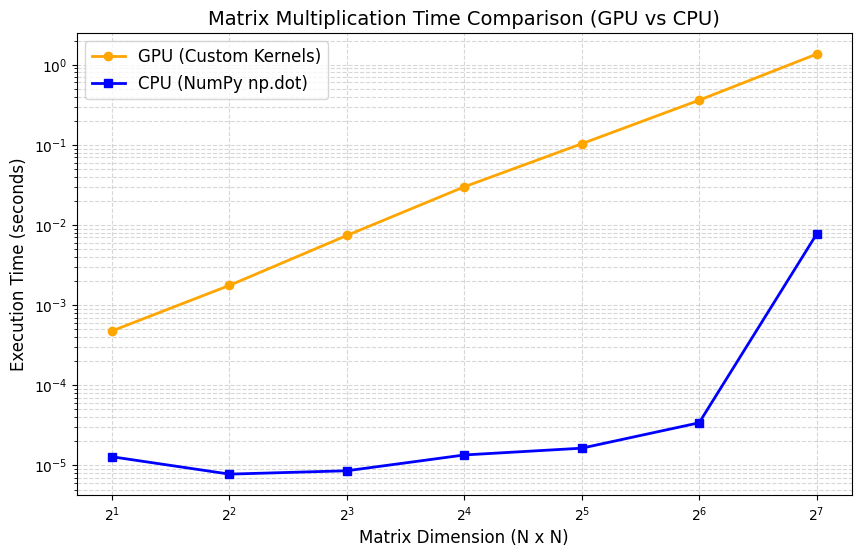

In [27]:
import time
import matplotlib.pyplot as plt

def benchmark_matrix_multiplication():
    # Test with square matrices of various sizes
    sizes = [2, 4, 8, 16, 32, 64, 128]
    gpu_times = []
    cpu_times = []

    # Warm-up run to initialize CUDA context fully
    temp_A = np.random.rand(4, 4).astype(np.float32)
    temp_B = np.random.rand(4, 4).astype(np.float32)
    _ = gpu_matrix_mul(temp_A, temp_B)

    for N in sizes:
        # Generate random square matrices of size N x N
        A_test = np.random.rand(N, N).astype(np.float32)
        B_test = np.random.rand(N, N).astype(np.float32)

        # Benchmark GPU (Custom Kernels)
        start_time = time.perf_counter()
        _ = gpu_matrix_mul(A_test, B_test)
        gpu_duration = time.perf_counter() - start_time
        gpu_times.append(gpu_duration)

        # Benchmark CPU (NumPy np.dot)
        start_time = time.perf_counter()
        _ = np.dot(A_test, B_test)
        cpu_duration = time.perf_counter() - start_time
        cpu_times.append(cpu_duration)

        print(f"Size {N}x{N} -> GPU: {gpu_duration:.6f}s | CPU: {cpu_duration:.6f}s")

    # Plotting the results
    plt.figure(figsize=(10, 6))
    plt.plot(sizes, gpu_times, marker='o', label='GPU (Custom Kernels)', color='orange', linewidth=2)
    plt.plot(sizes, cpu_times, marker='s', label='CPU (NumPy np.dot)', color='blue', linewidth=2)

    plt.title('Matrix Multiplication Time Comparison (GPU vs CPU)', fontsize=14)
    plt.xlabel('Matrix Dimension (N x N)', fontsize=12)
    plt.ylabel('Execution Time (seconds)', fontsize=12)
    plt.xscale('log', base=2)  # Logarithmic scale for better visualization of power-of-two sizes
    plt.yscale('log')          # Logarithmic scale for execution time
    plt.grid(True, which="both", linestyle='--', alpha=0.5)
    plt.legend(fontsize=12)
    plt.show()

benchmark_matrix_multiplication()

In [20]:
import numpy as np
try:
    import pycuda.driver as cuda
    import pycuda.autoinit
    from pycuda.compiler import SourceModule
except ImportError:
    # Install pycuda if not present
    !pip install pycuda
    import pycuda.driver as cuda
    import pycuda.autoinit
    from pycuda.compiler import SourceModule

# Define the single, unified CUDA kernel using your custom flattening strategy
# Flat indexing: k = N * j + i (where N is the matrix dimension)
# This works across multiple blocks in a 2D grid.
mod = SourceModule("""
__global__ void customMatrixMul(float *A, float *B, float *C, int N) {
    // Row and Col indices computed from block and thread indices
    int row = blockIdx.x * blockDim.x + threadIdx.x;
    int col = blockIdx.y * blockDim.y + threadIdx.y;

    if (row < N && col < N) {
        float sum = 0.0f;
        for (int j = 0; j < N; ++j) {
            // a[i][j] -> A[j * N + row]
            // b[j][k] -> B[col * N + j]
            float a_val = A[j * N + row];
            float b_val = B[col * N + j];
            sum += a_val * b_val;
        }
        // c[k][i] -> C[col * N + row]
        C[col * N + row] = sum;
    }
}
""")

custom_matmul_kernel = mod.get_function("customMatrixMul")

def run_custom_matmul(A, B):
    N = A.shape[0]

    # Flatten matrices using your specific indexing formula: k = N * j + i
    A_flat = A.flatten(order='F').astype(np.float32)
    B_flat = B.flatten(order='F').astype(np.float32)
    C_flat = np.zeros(N * N, dtype=np.float32)

    # Allocate and copy data to GPU
    A_gpu = cuda.to_device(A_flat)
    B_gpu = cuda.to_device(B_flat)
    C_gpu = cuda.mem_alloc(C_flat.nbytes)

    # Define safe block size (maximum 1024 threads total per block, e.g., 16x16 = 256 threads)
    block_size = 16
    block_dim = (block_size, block_size, 1)

    # Calculate required grid size to cover all elements in the N x N output matrix
    grid_dim = (int(np.ceil(N / block_size)), int(np.ceil(N / block_size)), 1)

    # Launch the kernel
    custom_matmul_kernel(A_gpu, B_gpu, C_gpu, np.int32(N), block=block_dim, grid=grid_dim)

    # Copy result back and reshape using 'F' order
    cuda.memcpy_dtoh(C_flat, C_gpu)
    return C_flat.reshape((N, N), order='F')

# Quick correctness validation
N = 20
A = np.arange(1, N*N + 1, dtype=np.float32).reshape((N, N))
B = np.arange(1, N*N + 1, dtype=np.float32).reshape((N, N))

res_gpu = run_custom_matmul(A, B)
res_cpu = np.dot(A, B)
assert np.allclose(res_gpu, res_cpu), "Verification Failed!"
print("Grid/Block safe version initialized & verified successfully!")

Grid/Block safe version initialized & verified successfully!


Size 16x16 -> GPU (Custom Grid): 0.000203s | CPU (NumPy): 0.000015s
Size 32x32 -> GPU (Custom Grid): 0.000755s | CPU (NumPy): 0.000017s
Size 64x64 -> GPU (Custom Grid): 0.000268s | CPU (NumPy): 0.000027s
Size 128x128 -> GPU (Custom Grid): 0.000338s | CPU (NumPy): 0.000144s
Size 256x256 -> GPU (Custom Grid): 0.000870s | CPU (NumPy): 0.000443s
Size 512x512 -> GPU (Custom Grid): 0.004370s | CPU (NumPy): 0.002658s
Size 1024x1024 -> GPU (Custom Grid): 0.026968s | CPU (NumPy): 0.019651s
Size 2048x2048 -> GPU (Custom Grid): 0.151141s | CPU (NumPy): 0.156525s
Size 4096x4096 -> GPU (Custom Grid): 1.015077s | CPU (NumPy): 1.153762s
Size 8192x8192 -> GPU (Custom Grid): 5.369192s | CPU (NumPy): 10.768943s


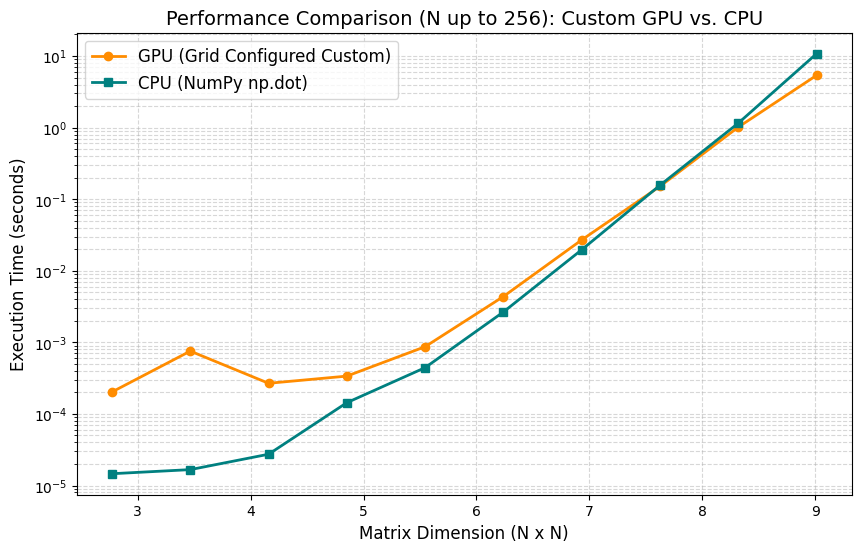

In [29]:
import time
import matplotlib.pyplot as plt

def benchmark_custom_vs_cpu_large():
    # Extended sizes to benchmark larger matrices
    sizes = [16, 32, 64, 128, 256, 512, 1024, 2048, 4096, 8192]
    gpu_times = []
    cpu_times = []

    # Warm-up run
    temp_matrix = np.random.rand(16, 16).astype(np.float32)
    _ = run_custom_matmul(temp_matrix, temp_matrix)

    for N in sizes:
        # Create random square matrices
        A_test = np.random.rand(N, N).astype(np.float32)
        B_test = np.random.rand(N, N).astype(np.float32)

        # Benchmark Custom GPU Matrix Multiplication
        t0 = time.perf_counter()
        _ = run_custom_matmul(A_test, B_test)
        gpu_duration = time.perf_counter() - t0
        gpu_times.append(gpu_duration)

        # Benchmark CPU Matrix Multiplication (NumPy)
        t1 = time.perf_counter()
        _ = np.dot(A_test, B_test)
        cpu_duration = time.perf_counter() - t1
        cpu_times.append(cpu_duration)

        print(f"Size {N}x{N} -> GPU (Custom Grid): {gpu_duration:.6f}s | CPU (NumPy): {cpu_duration:.6f}s")

    # Plotting
    plt.figure(figsize=(10, 6))
    plt.plot(np.log(sizes), gpu_times, marker='o', label='GPU (Grid Configured Custom)', color='darkorange', linewidth=2)
    plt.plot(np.log(sizes), cpu_times, marker='s', label='CPU (NumPy np.dot)', color='teal', linewidth=2)

    plt.title('Performance Comparison (N up to 256): Custom GPU vs. CPU', fontsize=14)
    plt.xlabel('Matrix Dimension (N x N)', fontsize=12)
    plt.ylabel('Execution Time (seconds)', fontsize=12)
    plt.yscale('log')
    plt.grid(True, which="both", linestyle='--', alpha=0.5)
    plt.legend(fontsize=12)
    plt.show()

benchmark_custom_vs_cpu_large()